# **4. HUẤN LUYỆN VÀ ĐÓNG GÓI MÔ HÌNH**

Có 4 bài toán = 2 mục tiêu (`Customers`, `Sales`) × 2 horizon (ngày mai h = 1, tuần tới h = 7). Mỗi bài toán gồm:
- **2 baseline** không học máy: cách người quản lý hay đoán.
- **LightGBM**: dự đoán mức trung bình.
- **LightGBM P80**: mức an toàn, 80% số ngày thực tế không vượt quá mức này.

Cuối notebook, mô hình được **đóng gói** ra file để web demo dùng.

Khởi tạo dữ liệu ban đầu.

In [1]:
from pathlib import Path
import json
import gc
import time
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import lightgbm as lgb
import joblib

import features as F
warnings.filterwarnings('ignore', module='lightgbm')

FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)
PROCESSED_DIR = Path('data/processed')
PRED_DIR = PROCESSED_DIR / 'predictions'
PRED_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = Path('models')
MODEL_DIR.mkdir(exist_ok=True)

def save_fig(name):
    """Lưu hình đang vẽ vào figures/<name>.png."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150)

with open(PROCESSED_DIR / 'config.json', encoding='utf-8') as f:
    cfg = {k: pd.Timestamp(v) for k, v in json.load(f).items()}
TRAIN_END, VALID_END = cfg['TRAIN_END'], cfg['VALID_END']

datasets = {}
for h in F.HORIZONS:
    d = pd.read_parquet(PROCESSED_DIR / f'dataset_h{h}.parquet')
    for col, cats in F.CATEGORIES.items():                 # đảm bảo danh mục giống hệt lúc dùng trên web
        d[col] = pd.Categorical(d[col], categories=cats)
    float_cols = d.select_dtypes('float64').columns        # float32 giảm một nửa bộ nhớ, đủ chính xác
    d[float_cols] = d[float_cols].astype('float32')
    datasets[h] = d

RUNS = [(target, h) for target in F.TARGETS for h in F.HORIZONS]

def run_name(target, h):
    return f'{target.lower()}_h{h}'          # customers_h1, customers_h7, sales_h1, sales_h7

print({h: d.shape for h, d in datasets.items()})
print(f'Bộ nhớ: {sum(d.memory_usage().sum() for d in datasets.values()) / 1e6:.0f} MB')

{1: (844338, 37), 7: (844338, 37)}
Bộ nhớ: 301 MB


**4.1 Chuẩn bị dữ liệu cho mô hình học máy**

Chia tập theo thời gian, cùng mốc với đồ án 1. Chỉ lưu **mặt nạ** (True/False) của từng tập, khi cần mới cắt dữ liệu ra, để tiết kiệm bộ nhớ (máy 8 GB RAM).

In [2]:
def split_masks(d):
    return {'train': d['Date'] <= TRAIN_END,
            'valid': (d['Date'] > TRAIN_END) & (d['Date'] <= VALID_END),
            'test':  d['Date'] > VALID_END}

masks = {h: split_masks(datasets[h]) for h in F.HORIZONS}

def part(h, name):
    """Cắt tập `name` ('train' / 'valid' / 'test') của bộ dữ liệu horizon h."""
    return datasets[h][masks[h][name]]

for name in ['train', 'valid', 'test']:
    p = part(1, name)
    print(f'{name:<6} {len(p):>8,} dòng | {p["Date"].min().date()} → {p["Date"].max().date()}')

train   754,242 dòng | 2013-01-01 → 2015-04-24
valid    43,098 dòng | 2015-04-25 → 2015-06-12
test     46,998 dòng | 2015-06-13 → 2015-07-31


Tạo một số hàm hỗ trợ. Dự đoán của mọi mô hình được gom vào bảng `results[bài toán]` (mỗi mô hình là một cột), rồi lưu ra file cho notebook 5 đọc lại mà không phải huấn luyện lại.

In [3]:
def rmspe(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0                      # tránh chia cho 0
    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2))

results = {}
for target, h in RUNS:
    d = datasets[h]
    results[run_name(target, h)] = pd.DataFrame({
        'Store': d['Store'], 'Date': d['Date'],
        'Split': np.select([d['Date'] <= TRAIN_END, d['Date'] <= VALID_END], ['train', 'valid'], 'test'),
        'actual': d[target].astype(float)})

def score_table(model_names, split='test'):
    """Bảng RMSPE và MAE của các mô hình trên một tập, cho cả 4 bài toán."""
    rows = []
    for run, res in results.items():
        part = res[res['Split'] == split]
        for m in model_names:
            rows.append({'Bài toán': run, 'Mô hình': m,
                         'RMSPE': rmspe(part['actual'], part[m]),
                         'MAE': np.mean(np.abs(part['actual'] - part[m]))})
    return pd.DataFrame(rows).pivot(index='Bài toán', columns='Mô hình', values=['RMSPE', 'MAE']).round(4)

def save_results():
    for run, res in results.items():
        res.to_parquet(PRED_DIR / f'{run}.parquet', index=False)

**4.2 Mô hình baseline**

Hai cách đoán phổ biến của người quản lý khi không có mô hình:
- **Tuần trước**: giống cùng thứ tuần trước (`lag_7`).
- **Cùng KM gần nhất**: giống ngày cùng thứ, **cùng trạng thái khuyến mãi** gần nhất trong 4 tuần trước (`same_promo`). Cách này rút ra từ phát hiện ở notebook 2: khuyến mãi chạy xen kẽ từng tuần.

Thiếu giá trị thì lùi về trung bình cùng thứ 4 tuần trước, rồi trung vị của cửa hàng. Cả hai baseline chỉ dùng dữ liệu từ 7 ngày trước trở về, nên **dùng được cho cả h = 1 và h = 7** (kết quả giống nhau ở hai horizon).

In [4]:
for target, h in RUNS:
    res = results[run_name(target, h)]
    fallback = part(h, 'train').groupby('Store')[target].median()
    res['Tuần trước'] = F.baseline(datasets[h], target, fallback, method='lag7')
    res['Cùng KM gần nhất'] = F.baseline(datasets[h], target, fallback, method='same_promo')
save_results()
score_table(['Tuần trước', 'Cùng KM gần nhất'])

RMSPE                         MAE           
Mô hình      Cùng KM gần nhất Tuần trước Cùng KM gần nhất Tuần trước
Bài toán                                                            
customers_h1           0.1198     0.2222          63.7523   126.3529
customers_h7           0.1198     0.2222          63.7523   126.3529
sales_h1               0.1559     0.3922         805.1256  2155.7936
sales_h7               0.1559     0.3922         805.1256  2155.7936

**Nhận xét:** baseline "Tuần trước" sai rất nhiều: RMSPE 0,222 với số khách và 0,392 với doanh thu (MAE 2.156, gần 1/3 doanh thu trung bình). Chỉ cần đổi sang "cùng thứ, cùng trạng thái khuyến mãi gần nhất", RMSPE giảm còn 0,120 (giảm 46%) và 0,156 (giảm 60%). Đây là bằng chứng trực tiếp cho phát hiện khuyến mãi xen kẽ từng tuần ở notebook 2. Từ đây, mốc để so sánh là baseline **"Cùng KM gần nhất"**, mốc khó vượt hơn.

**4.3 Huấn luyện mô hình LightGBM**

Cùng tham số với LightGBM của đồ án 1. Học trên `log1p(mục tiêu)` vì phân phối lệch phải, dừng sớm theo tập kiểm định.

In [5]:
PARAMS = dict(n_estimators=3000, learning_rate=0.1, num_leaves=127,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
              random_state=0, n_jobs=-1, verbose=-1)
models = {}

def train_lgb(target, h):
    cols = F.feature_columns(h)
    tr, va = part(h, 'train'), part(h, 'valid')
    X_tr, y_tr = tr[cols], np.log1p(tr[target])
    model = lgb.LGBMRegressor(**PARAMS)
    model.fit(X_tr, y_tr,
              eval_X=(X_tr, va[cols]), eval_y=(y_tr, np.log1p(va[target])),   # train + valid để vẽ quá trình học
              callbacks=[lgb.early_stopping(50, first_metric_only=True, verbose=False)])
    return model

for target, h in RUNS:
    run = run_name(target, h)
    t0 = time.time()
    models[run] = train_lgb(target, h)
    pred = np.expm1(models[run].predict(datasets[h][F.feature_columns(h)]))
    results[run]['LightGBM'] = np.clip(pred, 0, None)
    print(f'{run:<13} số cây: {models[run].best_iteration_:>5} | {time.time() - t0:.0f}s')
    gc.collect()                                   # giải phóng bộ nhớ trước mô hình tiếp theo
save_results()
score_table(['Cùng KM gần nhất', 'LightGBM'])

customers_h1  số cây:  1169 | 201s


customers_h7  số cây:   329 | 65s


sales_h1      số cây:   569 | 102s


sales_h7      số cây:   536 | 92s


RMSPE                       MAE          
Mô hình      Cùng KM gần nhất LightGBM Cùng KM gần nhất  LightGBM
Bài toán                                                         
customers_h1           0.1198   0.0816          63.7523   43.4387
customers_h7           0.1198   0.0919          63.7523   49.0877
sales_h1               0.1559   0.1055         805.1256  532.5404
sales_h7               0.1559   0.1142         805.1256  583.3915

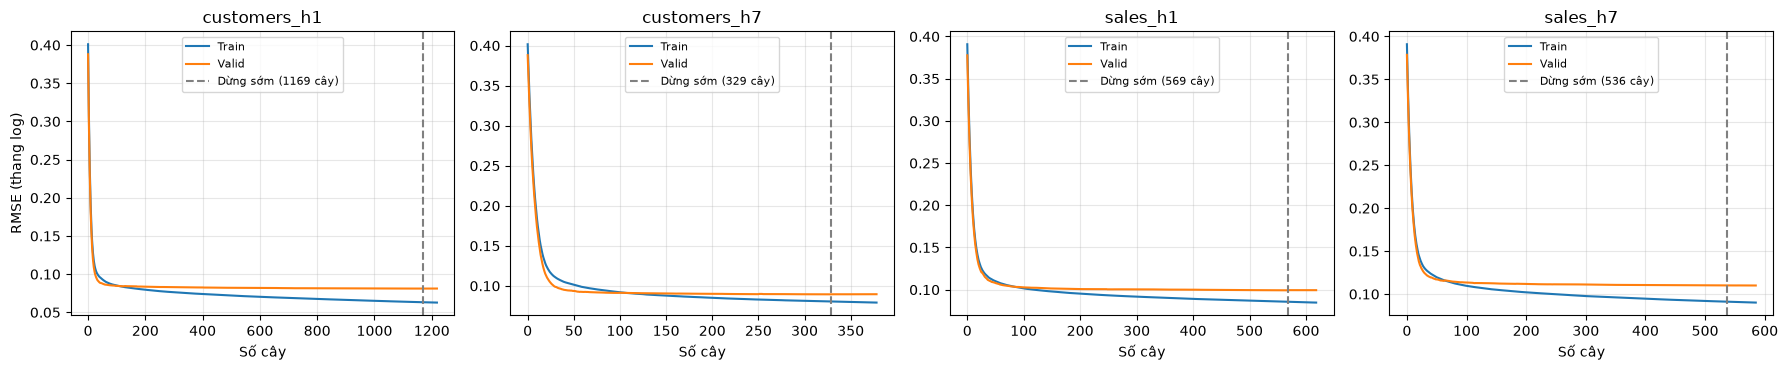

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, (target, h) in zip(axes, RUNS):
    m = models[run_name(target, h)]
    for key, label in zip(m.evals_result_, ['Train', 'Valid']):
        ax.plot(np.sqrt(m.evals_result_[key]['l2']), label=label)
    ax.axvline(m.best_iteration_, ls='--', color='gray', label=f'Dừng sớm ({m.best_iteration_} cây)')
    ax.set_title(run_name(target, h)); ax.set_xlabel('Số cây'); ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel('RMSE (thang log)')
save_fig('learning_curves')

**Nhận xét:** LightGBM tốt hơn rõ rệt baseline tốt nhất ở cả 4 bài toán:
- Số khách: RMSPE 0,0816 cho ngày mai (MAE 43,4 khách) và 0,0919 cho tuần tới (MAE 49,1).
- Doanh thu: RMSPE 0,1055 cho ngày mai (MAE 533) và 0,1142 cho tuần tới (MAE 583).

Mô hình số khách cho ngày mai dùng nhiều cây nhất (1.169), các mô hình còn lại dừng ở 329–569 cây. Trên biểu đồ quá trình học, đường valid giảm nhanh trong khoảng 100 cây đầu rồi đi ngang, không tăng trở lại; khoảng cách giữa train và valid nhỏ (khoảng 0,02 trên thang log), nên mô hình không bị học vẹt.

**4.4 Mô hình mức an toàn P80 (hồi quy phân vị)**

Đoán thiếu và đoán thừa gây hậu quả khác nhau: đoán thiếu thì thiếu nhân viên, hết hàng, mất khách; đoán thừa chỉ tốn thêm chi phí. Ngoài mức trung bình, cần thêm một **mức an toàn**.

Hồi quy phân vị với `alpha = 0.8` học ra mức mà **80% số ngày thực tế không vượt quá**. Hàm mất mát phạt đoán thiếu nặng gấp 4 lần đoán thừa (0,8 so với 0,2).

Học trên log vẫn đúng, vì phân vị không đổi qua phép biến đổi đơn điệu: phân vị 80% của log(số khách), đổi ngược bằng `expm1`, chính là phân vị 80% của số khách. Số cây lấy bằng số cây tối ưu của mô hình trung bình.

In [7]:
models_p80 = {}
for target, h in RUNS:
    run = run_name(target, h)
    t0 = time.time()
    cols = F.feature_columns(h)
    tr = part(h, 'train')
    params = {**PARAMS, 'n_estimators': models[run].best_iteration_}
    models_p80[run] = lgb.LGBMRegressor(objective='quantile', alpha=0.8, **params)
    models_p80[run].fit(tr[cols], np.log1p(tr[target]))
    results[run]['LightGBM P80'] = np.expm1(models_p80[run].predict(datasets[h][cols]))
    print(f'{run:<13} {time.time() - t0:.0f}s')
    del tr; gc.collect()
save_results()

coverage = pd.DataFrame({run: res.groupby('Split')
                              .apply(lambda g: (g['actual'] <= g['LightGBM P80']).mean() * 100, include_groups=False)
                         for run, res in results.items()}).T.round(1)
print('Tỷ lệ ngày thực tế ≤ mức P80 (%), mục tiêu là 80%:')
coverage[['train', 'valid', 'test']]

customers_h1  216s


customers_h7  70s


sales_h1      103s


sales_h7      104s


Tỷ lệ ngày thực tế ≤ mức P80 (%), mục tiêu là 80%:


Split,train,valid,test
customers_h1,80.0,74.6,77.1
customers_h7,80.0,77.5,78.3
sales_h1,80.0,76.0,77.2
sales_h7,80.1,73.7,75.9


**Nhận xét:** trên tập huấn luyện, đúng 80% số ngày thực tế ≤ P80, đúng như mục tiêu. Trên các tập mô hình chưa thấy, tỷ lệ này thấp hơn một chút: 73,7–77,5% ở tập kiểm định và 75,9–78,3% ở tập kiểm tra. Điều này bình thường, vì dữ liệu mới luôn khó đoán hơn dữ liệu đã học. Nếu cần đúng 80% thì có thể nâng `alpha` lên khoảng 0,83, hoặc nhân thêm một hệ số nhỏ tính trên tập kiểm định.

**4.5 Mức đóng góp của các đặc trưng**

Top 6 đặc trưng của mỗi bài toán (%):


,customers_h1,customers_h7,sales_h1,sales_h7
0,Customers_same_promo (48.5),Customers_same_promo (50.0),Sales_same_promo (74.0),Sales_same_promo (76.8)
1,Customers_dow_mean4 (35.2),Customers_dow_mean4 (37.1),Sales_lag_1 (6.4),Sales_dow_mean4 (4.3)
2,Customers_roll7 (3.5),LastPromo (1.6),Sales_dow_mean4 (5.4),Sales_lag_28 (2.5)
3,Customers_lag_1 (3.0),DaysSinceHoliday (1.3),Day (1.8),Day (2.1)
4,LastPromo (1.3),DaystoHoliday (1.1),Sales_roll7 (1.5),DaysSinceHoliday (2.0)
5,Customers_lag_14 (1.0),Day (1.1),DaystoHoliday (1.2),DaystoHoliday (1.6)


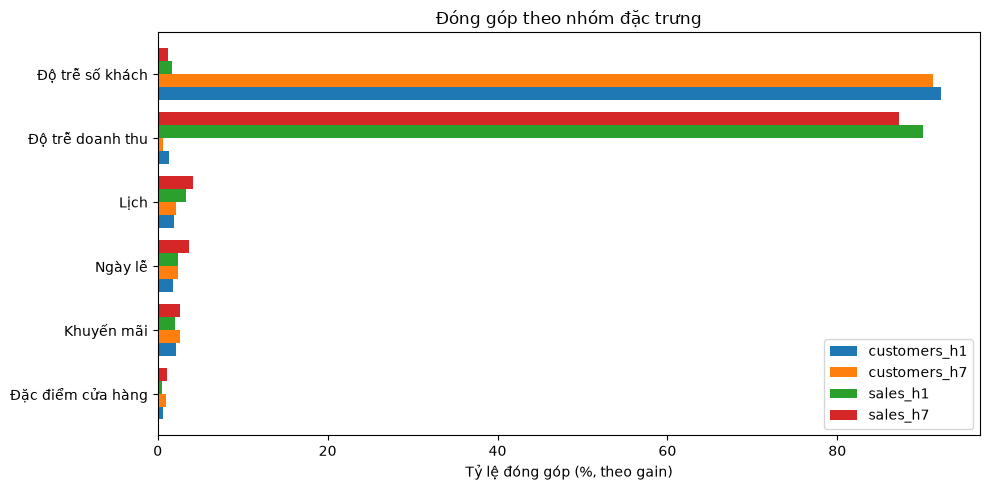

In [8]:
def feature_group(f):
    if f.startswith('Customers_'): return 'Độ trễ số khách'
    if f.startswith('Sales_'):     return 'Độ trễ doanh thu'
    if 'Holiday' in f:             return 'Ngày lễ'
    if 'Promo' in f:               return 'Khuyến mãi'
    if f in ('DayOfWeek', 'Day', 'Month'): return 'Lịch'
    return 'Đặc điểm cửa hàng'

importance = {}
for run, m in models.items():
    gain = pd.Series(m.booster_.feature_importance(importance_type='gain'), index=m.booster_.feature_name())
    importance[run] = 100 * gain / gain.sum()

by_group = pd.DataFrame({run: imp.groupby(imp.index.map(feature_group)).sum() for run, imp in importance.items()})
by_group = by_group.loc[by_group.mean(axis=1).sort_values().index]
ax = by_group.plot.barh(figsize=(10, 5), width=0.8)
ax.set_xlabel('Tỷ lệ đóng góp (%, theo gain)'); ax.set_title('Đóng góp theo nhóm đặc trưng')
save_fig('importance_groups')

print('Top 6 đặc trưng của mỗi bài toán (%):')
pd.DataFrame({run: [f'{f} ({v:.1f})' for f, v in imp.sort_values(ascending=False).head(6).items()]
              for run, imp in importance.items()})

**Nhận xét:** đặc trưng quan trọng nhất ở cả 4 bài toán là `same_promo` (giá trị của ngày cùng thứ, cùng trạng thái khuyến mãi gần nhất): chiếm 48–50% với số khách và 74–77% với doanh thu. Với số khách, `dow_mean4` (trung bình cùng thứ 4 tuần) đứng thứ hai (35–37%). Như vậy, mô hình học đúng điều đã phát hiện ở EDA: mức của cửa hàng theo thứ và theo chu kỳ khuyến mãi quyết định phần lớn. Độ trễ 1 ngày (`lag_1`) chỉ có ở mô hình h = 1 và đóng góp thêm 3,0% (số khách) và 6,4% (doanh thu). Phần đóng góp nhỏ này chính là khác biệt giữa dự báo ngày mai và dự báo tuần tới.

**4.6 Đóng gói mô hình**

Mỗi bài toán lưu thành một file `models/<bài toán>.joblib`, chứa **mọi thứ cần để dự đoán**, không chỉ mô hình:
- Mô hình trung bình và mô hình P80.
- Danh sách cột đúng thứ tự lúc học, và danh mục của cột category.
- Trung vị theo cửa hàng (để chạy baseline trên web).
- Ngày cuối dữ liệu huấn luyện, phiên bản thư viện, kết quả trên tập kiểm tra.

Mô hình đem đi dùng **chính là mô hình đã đánh giá** ở notebook 5 (học đến 24/04/2015).

In [9]:
for target, h in RUNS:
    run = run_name(target, h)
    test = results[run][results[run]['Split'] == 'test']
    package = {
        'model':         models[run],
        'model_p80':     models_p80[run],
        'features':      F.feature_columns(h),
        'categories':    F.CATEGORIES,
        'target':        target,
        'horizon':       h,
        'log_target':    True,
        'store_median':  part(h, 'train').groupby('Store')[target].median(),
        'trained_until': str(TRAIN_END.date()),
        'test_rmspe':    float(rmspe(test['actual'], test['LightGBM'])),
        'test_mae':      float(np.mean(np.abs(test['actual'] - test['LightGBM']))),
        'versions':      {'lightgbm': lgb.__version__, 'pandas': pd.__version__, 'numpy': np.__version__},
    }
    path = MODEL_DIR / f'{run}.joblib'
    joblib.dump(package, path, compress=3)
    print(f'Đã lưu {path} ({path.stat().st_size / 1e6:.1f} MB)')

Đã lưu models\customers_h1.joblib (10.3 MB)


Đã lưu models\customers_h7.joblib (2.9 MB)


Đã lưu models\sales_h1.joblib (5.1 MB)


Đã lưu models\sales_h7.joblib (4.8 MB)


**4.7 Kiểm tra gói mô hình**

Mô phỏng đúng cách web demo dùng mô hình:
1. Đọc dữ liệu gốc, tạo đặc trưng bằng `features.py`.
2. **Xoá** số khách / doanh thu của mọi ngày sau "hôm nay" (giả lập là chưa biết tương lai).
3. Nạp gói mô hình, dự đoán ngày mai.

Kết quả phải **trùng khớp** với dự đoán đã lưu trong notebook. Nếu trùng, notebook và web tạo đặc trưng giống hệt nhau và mô hình không nhìn thấy tương lai.

In [10]:
pkg = joblib.load(MODEL_DIR / 'customers_h1.joblib')
store_id, today = 262, pd.Timestamp('2015-07-30')
tomorrow = today + pd.Timedelta(days=1)

del datasets, masks; gc.collect()                                   # không cần nữa, giải phóng trước khi đọc dữ liệu gốc
base = F.add_features(F.make_full_calendar(F.load_raw('..')))        # web làm bước này một lần lúc khởi động
one = base[base['Store'] == store_id].copy()
actual = one.loc[one['Date'] == tomorrow, 'Customers'].iloc[0]
one.loc[one['Date'] > today, ['Sales', 'Customers']] = np.nan        # chưa biết tương lai
feat = F.add_lag_features(one, pkg['horizon'])
row = feat[feat['Date'] == tomorrow]

pred_web = np.expm1(pkg['model'].predict(row[pkg['features']]))[0]
p80_web = np.expm1(pkg['model_p80'].predict(row[pkg['features']]))[0]
saved = results['customers_h1']
pred_nb = saved.loc[(saved['Store'] == store_id) & (saved['Date'] == tomorrow), 'LightGBM'].iloc[0]
print(f'Cửa hàng {store_id}, dự báo cho {tomorrow.date()}:')
print(f'  Dự đoán kiểu web: {pred_web:.1f} khách (P80: {p80_web:.1f})')
print(f'  Dự đoán đã lưu  : {pred_nb:.1f} khách')
print(f'  Thực tế         : {actual:.0f} khách')
assert abs(pred_web - pred_nb) < 1e-6, 'Đặc trưng của web khác notebook!'
print('→ Trùng khớp.')

Cửa hàng 262, dự báo cho 2015-07-31:
  Dự đoán kiểu web: 3737.0 khách (P80: 3822.2)
  Dự đoán đã lưu  : 3737.0 khách
  Thực tế         : 3669 khách
→ Trùng khớp.


**Nhận xét:** 4 gói mô hình có tổng dung lượng khoảng 23 MB (10,3 / 2,9 / 5,1 / 4,8 MB). Phép kiểm tra cho cửa hàng 262: tạo đặc trưng kiểu web, xoá số liệu sau 30/07/2015 rồi dự đoán ngày 31/07, được 3.737 khách, **trùng khớp** với dự đoán trong notebook (thực tế 3.669 khách, sai 1,9%). Như vậy `features.py` cho cùng kết quả ở notebook và ở web, và mô hình không dùng số liệu của tương lai. Các gói này được web demo `app.py` sử dụng.